In [1]:
print("AI-Powered SMS Spam Detection System")
print("My Module 06 Final AI/ML Project")

AI-Powered SMS Spam Detection System
My Module 06 Final AI/ML Project


In [3]:
!pip install ucimlrepo

In [5]:
import pandas as pd
import zipfile
import urllib.request
from io import BytesIO

# Dataset download link
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download the ZIP file
with urllib.request.urlopen(url) as response:
    zip_data = BytesIO(response.read())

# Extract and read the dataset
with zipfile.ZipFile(zip_data) as zip_file:
    with zip_file.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)


In [6]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Check the column names and data types
print("\nDataset information:")
df.info()

# Count spam and legitimate messages
print("\nMessage counts:")
print(df["label"].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5572, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Message counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


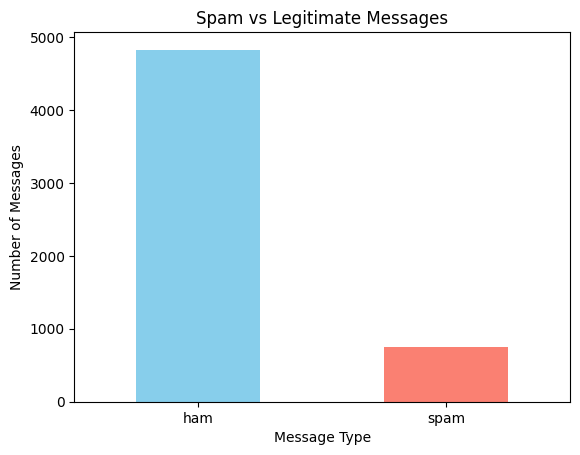

In [7]:
import matplotlib.pyplot as plt

# Count each type of message
label_counts = df["label"].value_counts()

# Create a bar chart
label_counts.plot(kind="bar", color=["skyblue", "salmon"])

plt.title("Spam vs Legitimate Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [8]:
# Convert text labels into numbers
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

# Display the original and converted labels
print(df[["label", "label_num"]].head())

# Check the converted label counts
print("\nNumeric label counts:")
print(df["label_num"].value_counts())

  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0

Numeric label counts:
label_num
0    4825
1     747
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

# Input: SMS text
X = df["message"]

# Output: spam (1) or legitimate (0)
y = df["label_num"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4457
Testing messages: 1115


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# Learn word patterns from training messages and convert them into numbers
X_train_tfidf = vectorizer.fit_transform(X_train)

# Convert test messages using the same learned word patterns
X_test_tfidf = vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 7668)
Testing data shape: (1115, 7668)


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF converter
tfidf = TfidfVectorizer()

# Learn from training messages and convert them into numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing messages using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 7668)
Testing data shape: (1115, 7668)


In [12]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
model = MultinomialNB()

# Train the model using the training data
model.fit(X_train_tfidf, y_train)

print("Spam detection model trained successfully!")

Spam detection model trained successfully!


In [13]:
# Predict labels for the test messages
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("First 10 predicted labels:")
print(y_pred[:10])

Predictions completed!
First 10 predicted labels:
[0 0 0 1 0 0 0 0 0 0]


In [14]:
from sklearn.metrics import accuracy_score, classification_report

# Compare actual labels with predicted labels
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham (Not Spam)", "Spam"]
))

Model Accuracy: 96.05 %

Classification Report:
                precision    recall  f1-score   support

Ham (Not Spam)       0.96      1.00      0.98       966
          Spam       1.00      0.70      0.83       149

      accuracy                           0.96      1115
     macro avg       0.98      0.85      0.90      1115
  weighted avg       0.96      0.96      0.96      1115



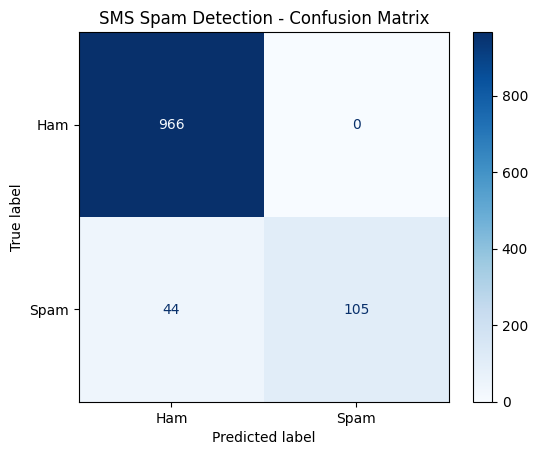

Confusion Matrix:
[[966   0]
 [ 44 105]]


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display it as a chart
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(cmap="Blues")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [16]:
def predict_sms(message):
    # Convert the message into TF-IDF features
    message_tfidf = tfidf.transform([message])

    # Predict the message category
    prediction = model.predict(message_tfidf)[0]

    if prediction == 1:
        return "Spam"
    else:
        return "Not Spam"


# Test with a new message
new_message = input("Enter an SMS message: ")

result = predict_sms(new_message)

print("Prediction:", result)

Enter an SMS message: Congratulations! You have won a free prize. Call now!
Prediction: Spam


In [17]:
import joblib

# Save the trained model
joblib.dump(model, "spam_detection_model.pkl")

# Save the TF-IDF converter
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!
